# Pertemuan 11 — Lab Starter: Transformer & Attention
Isi bagian bertanda `____` (TODO). Jalankan sel dari atas ke bawah.
- **Bagian A (10 mnt)**: attention dari nol, NumPy saja.
- **Bagian B (15 mnt)**: kantong kata vs model pre-trained. Jalankan di **Google Colab** (butuh internet).
- **Bagian C (12 mnt)**: LLM lokal lewat Ollama. Paling mudah di **Google Colab** juga: jalankan sel C0 dulu, ia memasang Ollama dan mengunduh model kecil.

Semua bagian bisa dikerjakan sendiri di Colab. Mulai dari sel Bagian 0a untuk mengunggah dua CSV.

In [1]:
# Nama / NIM: Salsabilla erlina malix/2553110008
# BAGIAN 0a (HANYA di Google Colab): unggah dua berkas CSV. Klik 'Choose Files', pilih keduanya.
try:
    from google.colab import files
    files.upload()
except ImportError:
    print("Bukan Colab: pastikan dua CSV ada di folder yang sama dengan notebook ini.")

Saving Pertemuan-11-Paket-HandsOn-Mahasiswa.zip to Pertemuan-11-Paket-HandsOn-Mahasiswa.zip


In [6]:
import zipfile
import os

zip_path = 'Pertemuan-11-Paket-HandsOn-Mahasiswa.zip'
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, 'r') as zip_ref:
        zip_ref.extractall('.')
    print("Ekstraksi selesai! Berkas CSV siap digunakan.")
else:
    print(f"Berkas {zip_path} tidak ditemukan. Pastikan Anda sudah mengunggahnya pada sel di atas.")

Ekstraksi selesai! Berkas CSV siap digunakan.


In [7]:
# BAGIAN 0 (sudah disediakan): data
import numpy as np, pandas as pd
import os, glob
np.set_printoptions(precision=4, suppress=True)

# Mencari file secara dinamis jika berada di dalam subfolder
path_latih = glob.glob('**/ulasan_latih_600.csv', recursive=True)
path_uji = glob.glob('**/ulasan_uji_48.csv', recursive=True)

latih_file = path_latih[0] if path_latih else "ulasan_latih_600.csv"
uji_file = path_uji[0] if path_uji else "ulasan_uji_48.csv"

latih = pd.read_csv(latih_file)
uji   = pd.read_csv(uji_file)
print(latih.shape, uji.shape)

def softmax(z):
    e = np.exp(z - z.max(axis=1, keepdims=True))
    return e / e.sum(axis=1, keepdims=True)

(600, 3) (48, 4)


## Bagian A — attention dari nol
Target: bobot 'bersih' ke 'tidak' = 0.807.

In [8]:
# BAGIAN A (10 mnt): attention dari nol untuk "kamar tidak bersih"
kata = ["kamar", "tidak", "bersih"]
X  = np.array([[1., 0., 0.], [0., 1., 0.], [0., 0., 1.]])
Wq = np.array([[0., 1.], [0., 0.], [1., 0.]])
Wk = np.array([[0., 1.], [3., 0.], [0., 1.]])
Wv = np.array([[0., 0.], [0., 1.], [1., 0.]])
Q, K, V = X @ Wq, X @ Wk, X @ Wv         # TODO-1
skala = (Q @ K.T) / np.sqrt(K.shape[1])    # TODO-2: skor = Q @ K.T
A = softmax(skala)                        # TODO-3
Z = A @ V                                 # TODO-4
print("A =\n", A); print("Z =\n", Z)
print("bobot 'bersih' ke 'tidak':", round(float(A[2, 1]), 3))

A =
 [[0.4011 0.1978 0.4011]
 [0.3333 0.3333 0.3333]
 [0.0967 0.8066 0.0967]]
Z =
 [[0.4011 0.1978]
 [0.3333 0.3333]
 [0.0967 0.8066]]
bobot 'bersih' ke 'tidak': 0.807


In [ ]:
# Cek mandiri Bagian A
ok = abs(float(A[2, 1]) - 0.8066) < 0.001
print("BENAR: bobot 'bersih' ke 'tidak' =", round(float(A[2, 1]), 3) if ok else "")
if not ok:
    print("Belum cocok. Cek: K ditranspos (K.T)? sudah dibagi akar d_k? softmax per baris?")

BENAR: bobot 'bersih' ke 'tidak' = 0.807


## Bagian B — kantong kata vs pre-trained
Isi tabel di slide dengan hasil `akurasi`.

In [9]:
# BAGIAN B (15 mnt): kantong kata vs model pre-trained (Colab)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
vek = TfidfVectorizer()
svm = LinearSVC(random_state=7).fit(vek.fit_transform(latih["ulasan"]), latih["label"])
uji["tebak_bow"] = svm.predict(vek.transform(uji["ulasan"]))
# !pip install -q transformers torch
from transformers import pipeline
model = "w11wo/indonesian-roberta-base-sentiment-classifier"
pembaca = pipeline("text-classification", model=model, top_k=None)
def pilih(hasil):          # bandingkan positive vs negative
    skor = {h["label"]: h["score"] for h in hasil}
    return "positif" if skor["positive"] >= skor["negative"] else "negatif"
hasil = pembaca(list(uji["ulasan"]))
uji["tebak_tf"] = [pilih(h) for h in hasil]   # TODO-5
tabel = uji.assign(bow=uji["tebak_bow"] == uji["label"],
                   tf=uji["tebak_tf"] == uji["label"])
print(tabel.groupby("jenis")[["bow", "tf"]].mean().round(3))   # TODO-6: salin angkanya ke lembar hasil

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/328 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/808k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/467k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.38M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

           bow     tf
jenis                
biasa    1.000  1.000
gaul     0.750  1.000
kontras  0.750  0.917
negasi   0.417  1.000


## Bagian C — LLM lokal
Di Colab: jalankan sel C0 dulu (3-6 menit). Di laptop sendiri yang sudah ada Ollama: lewati C0. Model awal `qwen2.5:1.5b`; ganti sesuai `ollama list` bila perlu. Lalu isi TODO-7 dan TODO-8.

In [10]:
# BAGIAN C0 (HANYA di Google Colab): pasang Ollama dan unduh model kecil. Sekali jalan, sekitar 3-6 menit.
import subprocess, time, shutil
if shutil.which("ollama") is None:
    subprocess.run("apt-get -qq install -y zstd", shell=True)
    subprocess.run("curl -fsSL https://ollama.com/install.sh | sh", shell=True)
subprocess.Popen(["ollama", "serve"], stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
time.sleep(8)
subprocess.run(["ollama", "pull", "qwen2.5:1.5b"])
print(subprocess.run(["ollama", "list"], capture_output=True, text=True).stdout)

NAME            ID              SIZE      MODIFIED               
qwen2.5:1.5b    65ec06548149    986 MB    Less than a second ago    



In [11]:
# BAGIAN C (12 mnt): LLM lokal (Ollama) pada 12 ulasan negasi
import requests
OLLAMA, MODEL = "http://localhost:11434", "qwen2.5:1.5b"
def tanya(ulasan, contoh=""):
    perintah = ("Kamu penilai ulasan hotel. Jawab HANYA satu kata: "
                "positif atau negatif.\n" + contoh +
                "Ulasan: " + ulasan + "\nJawaban:")
    r = requests.post(OLLAMA + "/api/chat", timeout=120, json={
        "model": MODEL, "stream": False, "options": {"temperature": 0},
        "messages": [{"role": "user", "content": perintah}]})
    return r.json()["message"]["content"].strip().lower()
negasi = uji[uji["jenis"] == "negasi"]
tebak = [tanya(u) for u in negasi["ulasan"]]   # TODO-7: zero-shot
cocok = [t.startswith(l) for t, l in zip(tebak, negasi["label"])]
print("akurasi LLM (negasi):", sum(cocok), "dari", len(cocok))

# TODO-8: few-shot. Dua contoh diambil dari DATA LATIH (id 1 negatif, id 2 positif), bukan data uji
contoh = ("Ulasan: Hotel ini mengecewakan, staf berisik, saya kecewa.\nJawaban: negatif\n"
          "Ulasan: Kasur banget memuaskan dan kolam tenang.\nJawaban: positif\n")
tebak_fs = [tanya(u, contoh) for u in negasi["ulasan"]]
cocok_fs = [t.startswith(l) for t, l in zip(tebak_fs, negasi["label"])]
print("akurasi LLM (negasi, few-shot):", sum(cocok_fs), "dari", len(cocok_fs))

akurasi LLM (negasi): 12 dari 12
akurasi LLM (negasi, few-shot): 12 dari 12


SS1-bobot-0807.png 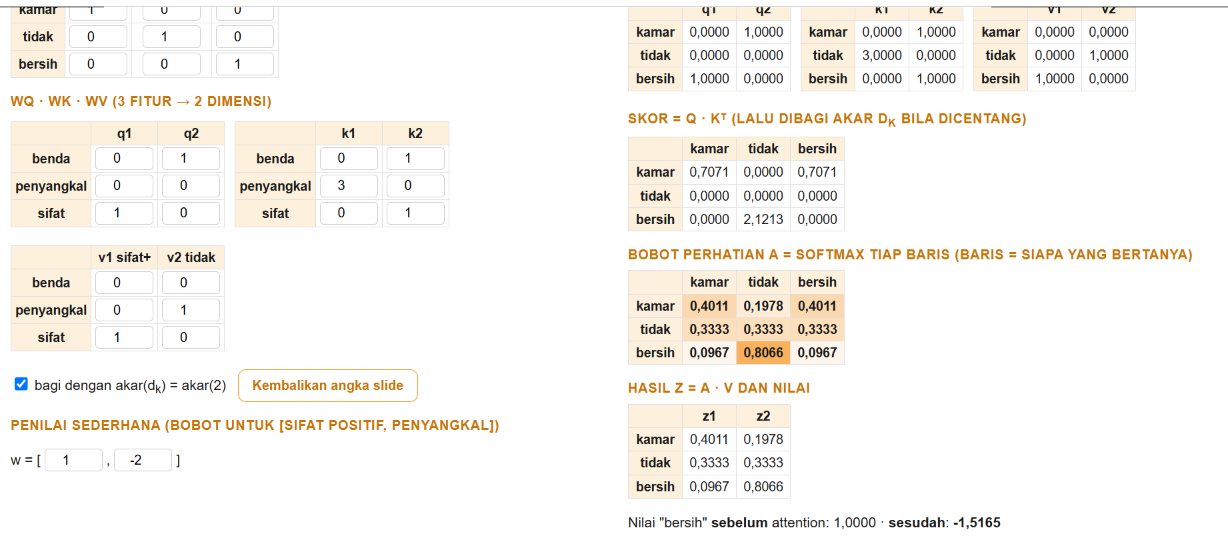

SS2-tabel-akurasi.png 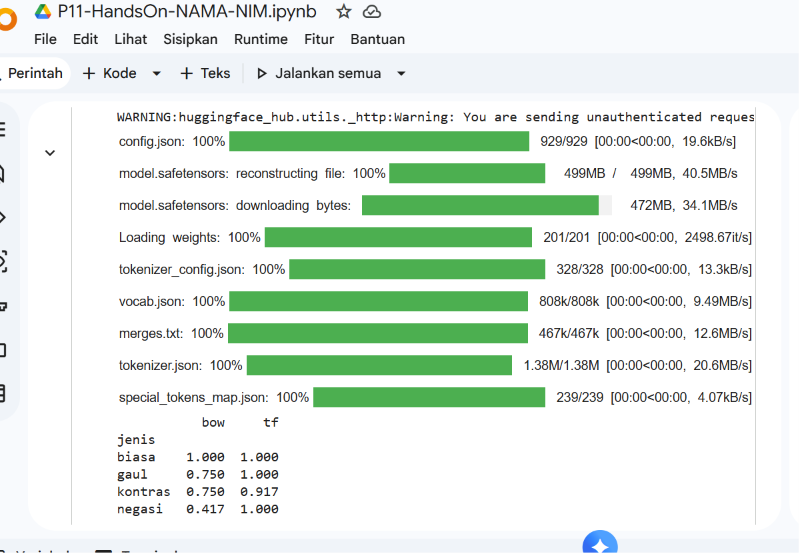

SS3-hasil-LLM.png 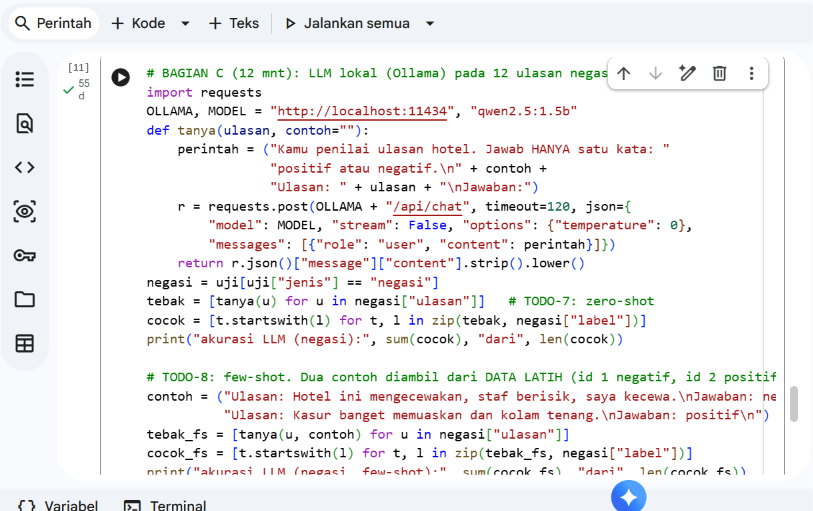